# 01 — HOG + SVM starter
Setup and data loading work now. Model sections are intentionally TODOs: no HOG extraction, training, tuned hyperparameters, or results are supplied.

## 1. Setup

### Environment and dataset configuration
**The one dataset path you may need to change is `DRIVE_DATA_ROOT` below.** It is an example, not a known shared-folder location. Point to the folder directly containing `Train.csv`, `Test.csv`, `Train/`, and `Test/`. If the folder is under "Shared with me", add a shortcut under My Drive first.

Colab defaults to Drive; local runs default to `Dataset/raw/`. Set `USE_DRIVE = False` to use repository data in Colab. Run cells in order. No API keys are needed.

In [8]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = IN_COLAB
# CHANGE THIS ONE DATASET PATH to your own shared Drive folder/shortcut:
DRIVE_DATA_ROOT = "/content/drive/MyDrive/CP467_Traffic_Signs/data/raw"
print("Running in Colab:", IN_COLAB)
print("Python:", sys.version)

Running in Colab: True
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


### Mount Drive and locate project code
Opening a GitHub notebook in Colab does not clone its Python files. This cell finds a local project checkout or clones it once in Colab. For a code checkout stored on Drive, change the working directory to that checkout before this cell (see README).

In [9]:
import os
import subprocess

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path("/content/CP467GroupProject")
    if not PROJECT_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/Davy-Chu/CP467GroupProject.git", str(PROJECT_ROOT)],
            check=True,
        )
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise RuntimeError("Open from the project checkout or change directory to its root first.")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/CP467GroupProject


### Dependencies
Colab often includes these libraries. Leave installation off first; if an import fails, set `INSTALL_DEPENDENCIES = True`, run this cell, restart the runtime if requested, then rerun from the top with installation off. Avoid replacing a working Colab GPU environment unnecessarily.

In [10]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")],
        check=True,
    )

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skimage
import sklearn
import torch
import torchvision
import seaborn

for library in (cv2, np, pd, matplotlib, skimage, sklearn, torch, torchvision, seaborn):
    print(f"{library.__name__}: {library.__version__}")

cv2: 5.0.0
numpy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0
skimage: 0.25.2
sklearn: 1.6.1
torch: 2.14.1+cpu
torchvision: 0.29.1+cpu
seaborn: 0.13.2


In [11]:
from src.config import (
    NUM_CLASSES, IMAGE_SIZE, RANDOM_SEED, REPO_DATA_ROOT,
    RESULTS_DIR, MODELS_DIR, CONDITIONS, DEGRADATION_PARAMS,
    get_data_root, seed_everything,
)
from src.data_utils import (
    validate_dataset, load_metadata, load_image,
    make_train_validation_split, split_fingerprint,
)
from src.degradations import (
    apply_condition, reduce_brightness, add_noise, apply_motion_blur,
    equalize_histogram, gaussian_filter,
)

seed_everything()
DATA_ROOT = get_data_root(USE_DRIVE, DRIVE_DATA_ROOT)
print("Selected data root:", DATA_ROOT)
print("Repository fallback:", REPO_DATA_ROOT)
print("Shared conditions:", DEGRADATION_PARAMS)

Selected data root: /content/drive/.shortcut-targets-by-id/1FsBmRpQD63fnmP2odgoMoYPisfonn987/CP467_Traffic_Signs/data/raw
Repository fallback: /content/CP467GroupProject/Dataset/raw
Shared conditions: {'brightness': {'factor': 0.5}, 'noise': {'std': 0.05}, 'motion_blur': {'kernel_size': 9}}


## 2. Load Dataset

Validation requires all 43 classes, the full 39,209/12,630 labeled image counts, and every referenced file. It fails if anything required is missing. The default decodes one image per class in each split; use `check_images="all"` for a slower full corruption scan on Drive. Do not disable the count checks to work around an unfinished upload.

In [12]:
# This must pass before either team begins model development.
training_metadata, test_metadata = validate_dataset(DATA_ROOT, check_images="sample")
train_metadata, validation_metadata = make_train_validation_split(training_metadata)
SPLIT_ID = split_fingerprint(train_metadata, validation_metadata)
print(f"Training subset: {len(train_metadata):,}")
print(f"Validation subset: {len(validation_metadata):,}")
print(f"Official test (final evaluation only): {len(test_metadata):,}")
print("Split ID (must match across teammates):", SPLIT_ID)

Dataset root: /content/drive/.shortcut-targets-by-id/1FsBmRpQD63fnmP2odgoMoYPisfonn987/CP467_Traffic_Signs/data/raw
Train/: 5,760 PNG images present (expected 39,209).
Test/: 12,630 PNG images present (expected 12,630).
Decoding 43 Test images (sample check)...
Test.csv: 12,630 rows, 43 classes.


DatasetValidationError: Dataset is NOT ready:
- Train/ has 5,760 PNG images; expected 39,209.
- Train: 33,449 referenced images missing; examples: ['Train/12/00012_00000_00000.png', 'Train/12/00012_00000_00001.png', 'Train/12/00012_00000_00002.png', 'Train/12/00012_00000_00003.png', 'Train/12/00012_00000_00004.png']
Restore the original missing GTSRB files or choose a complete Drive copy. Meta.csv is class metadata, not training/test labels.

## 3. Preprocessing
Apply any experimental condition to the common RGB image before grayscale conversion. Fit learned preprocessing on the training subset only.

In [14]:
# TODO: Convert the common resized RGB images to grayscale; document normalization.
# Compare optional equalize_histogram / gaussian_filter separately, with parameters logged.



def preprocess_for_hog(image, preprocessing="none"):
    if image.shape != (32, 32, 3):
        raise ValueError("Expected a 32x32 RGB image.")

    if image.dtype != np.uint8:
        raise TypeError("Expected a uint8 RGB image.")

    if preprocessing == "equalize":
        image = equalize_histogram(image)
    elif preprocessing == "gaussian":
        image = gaussian_filter(image, kernel_size=3, sigma=1.0)
    elif preprocessing != "none":
        raise ValueError(f"Unknown preprocessing: {preprocessing}")

    grayscale = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    grayscale = grayscale.astype(np.float32) / 255.0

    return grayscale


All preprocessing tests passed!
Output shape: (32, 32)
Pixel range: 0.0 1.0


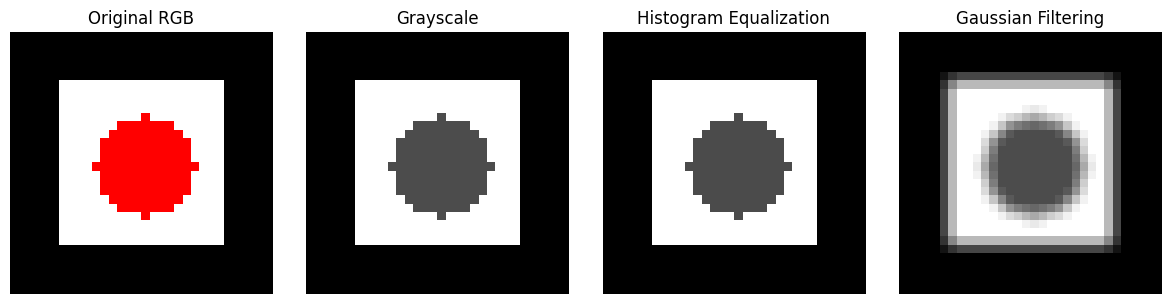

In [15]:

test_image = np.zeros((32, 32, 3), dtype=np.uint8)

cv2.rectangle(test_image, (6, 6), (25, 25), (255, 255, 255), -1)
cv2.circle(test_image, (16, 16), 6, (255, 0, 0), -1)

processed_image = preprocess_for_hog(test_image)

assert processed_image.shape == (32, 32)
assert processed_image.dtype == np.float32
assert 0.0 <= processed_image.min()
assert processed_image.max() <= 1.0

equalized_image = preprocess_for_hog(test_image, "equalize")
filtered_image = preprocess_for_hog(test_image, "gaussian")

assert equalized_image.shape == (32, 32)
assert filtered_image.shape == (32, 32)

print("All preprocessing tests passed!")
print("Output shape:", processed_image.shape)
print("Pixel range:", processed_image.min(), processed_image.max())

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

images = [
    test_image,
    processed_image,
    equalized_image,
    filtered_image,
]

titles = [
    "Original RGB",
    "Grayscale",
    "Histogram Equalization",
    "Gaussian Filtering",
]

for axis, image, title in zip(axes, images, titles):
    axis.imshow(image, cmap="gray" if image.ndim == 2 else None)
    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()


## 4. HOG Feature Extraction

In [16]:
# TODO: Choose and document HOG settings. Extract features for the shared subsets.
# Use skimage.feature.hog; tune settings on validation only.



from skimage.feature import hog

HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (8, 8),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
}


def extract_hog_features(image, preprocessing="none"):
    grayscale = preprocess_for_hog(image, preprocessing)

    features = hog(
        grayscale,
        **HOG_PARAMS,
        feature_vector=True,
    )

    return features.astype(np.float32)


def extract_hog_dataset(metadata, preprocessing="none"):
    features = []
    labels = []

    for row in metadata.itertuples(index=False):
        image = load_image(DATA_ROOT, row.Path)
        hog_features = extract_hog_features(image, preprocessing)

        features.append(hog_features)
        labels.append(row.ClassId)

    return np.asarray(features), np.asarray(labels)


HOG feature extraction passed!
Feature vector shape: (324,)
Feature count: 324


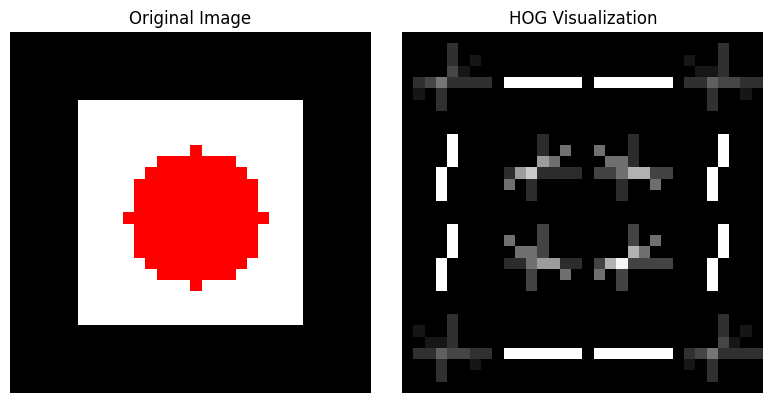

In [17]:

test_features = extract_hog_features(test_image)

assert test_features.shape == (324,)
assert np.all(np.isfinite(test_features))

print("HOG feature extraction passed!")
print("Feature vector shape:", test_features.shape)
print("Feature count:", len(test_features))

grayscale = preprocess_for_hog(test_image)

_, hog_visualization = hog(
    grayscale,
    **HOG_PARAMS,
    visualize=True,
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(test_image)
axes[0].set_title("Original Image")

axes[1].imshow(hog_visualization, cmap="gray")
axes[1].set_title("HOG Visualization")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()


## 5. Train SVM

In [18]:
# TODO: Build the SVM pipeline. Fit scaling (if used) and SVM only on train_metadata.
# Choose model settings with validation; do not inspect test scores for tuning.


import time

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


def train_svm(x_train, y_train, x_val, y_val, c_values=(0.1, 1, 10)):
    best_model = None
    best_accuracy = -1
    best_c = None
    results = []

    for c in c_values:
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=c, gamma="scale"),
        )

        start_time = time.perf_counter()
        model.fit(x_train, y_train)
        training_time = time.perf_counter() - start_time

        predictions = model.predict(x_val)
        validation_accuracy = accuracy_score(y_val, predictions)

        results.append({
            "C": c,
            "validation_accuracy": validation_accuracy,
            "training_time_seconds": training_time,
        })

        print(
            f"C={c} | "
            f"Validation accuracy={validation_accuracy:.4f} | "
            f"Training time={training_time:.2f}s"
        )

        if validation_accuracy > best_accuracy:
            best_accuracy = validation_accuracy
            best_model = model
            best_c = c

    print(f"\nBest C: {best_c}")
    print(f"Best validation accuracy: {best_accuracy:.4f}")

    return best_model, pd.DataFrame(results)


In [19]:

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

x_sample, y_sample = make_classification(
    n_samples=200,
    n_features=324,
    n_informative=20,
    n_redundant=10,
    n_classes=4,
    random_state=42,
)

x_sample_train, x_sample_val, y_sample_train, y_sample_val = train_test_split(
    x_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample,
)

test_model, test_results = train_svm(
    x_sample_train,
    y_sample_train,
    x_sample_val,
    y_sample_val,
)

assert test_model is not None
assert len(test_results) == 3
assert test_results["validation_accuracy"].between(0, 1).all()

print("\nSVM training test passed!")
print(test_results)


C=0.1 | Validation accuracy=0.2500 | Training time=0.03s
C=1 | Validation accuracy=0.4500 | Training time=0.03s
C=10 | Validation accuracy=0.4250 | Training time=0.02s

Best C: 1
Best validation accuracy: 0.4500

SVM training test passed!
      C  validation_accuracy  training_time_seconds
0   0.1                0.250               0.034458
1   1.0                0.450               0.030978
2  10.0                0.425               0.022901


## 6. Validation

In [20]:
# TODO: Evaluate on validation_metadata using accuracy and macro F1 over all 43 classes.
# Fix model and preprocessing choices before final test evaluation.


import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


def evaluate_svm(model, x_test, y_test):
    start_time = time.perf_counter()
    predictions = model.predict(x_test)
    inference_time = time.perf_counter() - start_time

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0,
    )

    average_inference_time = inference_time / len(x_test)

    metrics = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "total_inference_seconds": inference_time,
        "average_inference_seconds": average_inference_time,
    }

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1-score: {macro_f1:.4f}")
    print(f"Average inference: {average_inference_time * 1000:.4f} ms/image")

    return metrics, predictions


def plot_confusion_matrix(y_true, predictions, title):
    matrix = confusion_matrix(y_true, predictions)

    fig, ax = plt.subplots(figsize=(10, 8))

    display = ConfusionMatrixDisplay(confusion_matrix=matrix)
    display.plot(ax=ax, cmap="Blues", colorbar=True)

    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def show_prediction_examples(y_true, predictions, max_examples=5):
    correct_indices = np.where(y_true == predictions)[0]
    incorrect_indices = np.where(y_true != predictions)[0]

    print("Correct predictions:")
    for index in correct_indices[:max_examples]:
        print(f"  Index {index}: True={y_true[index]}, Predicted={predictions[index]}")

    print("\nIncorrect predictions:")
    for index in incorrect_indices[:max_examples]:
        print(f"  Index {index}: True={y_true[index]}, Predicted={predictions[index]}")


Accuracy: 0.4500
Macro F1-score: 0.4183
Average inference: 0.1486 ms/image

SVM evaluation tests passed!


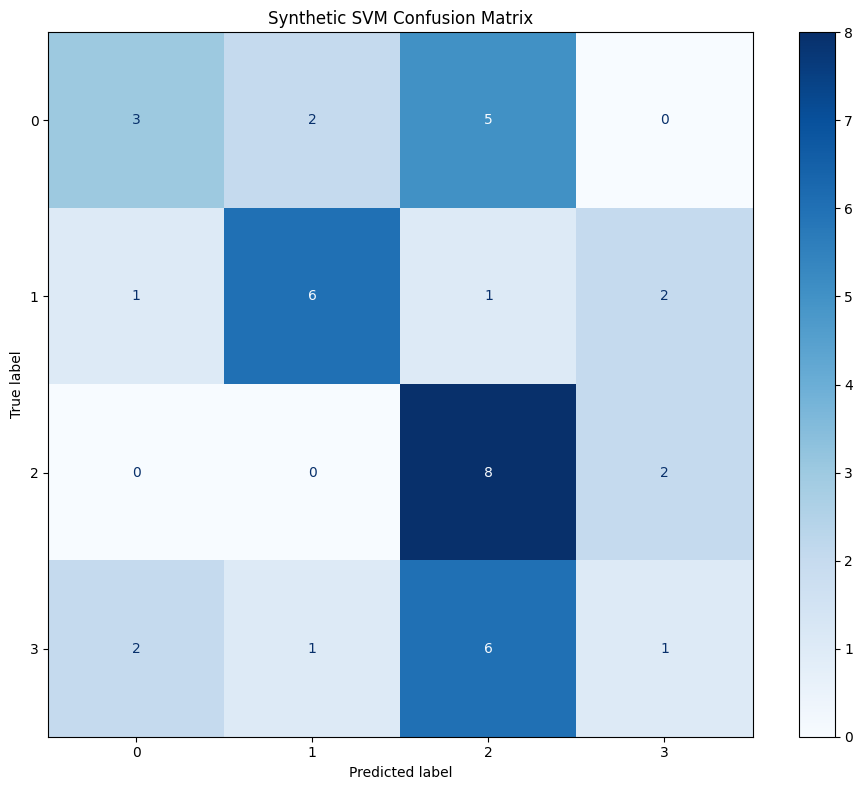

Correct predictions:
  Index 1: True=2, Predicted=2
  Index 3: True=1, Predicted=1
  Index 5: True=3, Predicted=3
  Index 8: True=2, Predicted=2
  Index 11: True=2, Predicted=2

Incorrect predictions:
  Index 0: True=0, Predicted=1
  Index 2: True=0, Predicted=2
  Index 4: True=3, Predicted=2
  Index 6: True=3, Predicted=1
  Index 7: True=2, Predicted=3


In [21]:

test_metrics, test_predictions = evaluate_svm(
    test_model,
    x_sample_val,
    y_sample_val,
)

assert 0 <= test_metrics["accuracy"] <= 1
assert 0 <= test_metrics["macro_f1"] <= 1
assert len(test_predictions) == len(y_sample_val)

print("\nSVM evaluation tests passed!")

plot_confusion_matrix(
    y_sample_val,
    test_predictions,
    "Synthetic SVM Confusion Matrix",
)

show_prediction_examples(
    y_sample_val,
    test_predictions,
)


## 7. Clean Test Evaluation

In [32]:
# TODO: Evaluate the frozen pipeline on test_metadata with condition='clean'.
# Use sklearn.metrics.accuracy_score and f1_score(..., average='macro',
# labels=list(range(NUM_CLASSES)), zero_division=0).


from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

RUN_FINAL_EVALUATION = False

def extract_condition_features(metadata, condition="clean", preprocessing="none"):
    features = []
    labels = []

    for row in metadata.itertuples(index=False):
        image = load_image(DATA_ROOT, row.Path)
        image = apply_condition(image, condition, image_id=row.Path)

        features.append(extract_hog_features(image, preprocessing))
        labels.append(row.ClassId)

    return np.asarray(features, dtype=np.float32), np.asarray(labels)


def evaluate_condition(model, metadata, condition="clean", preprocessing="none"):
    x, y = extract_condition_features(metadata, condition, preprocessing)
    predictions = model.predict(x)

    return {
        "condition": condition,
        "preprocessing": preprocessing,
        "accuracy": accuracy_score(y, predictions),
        "macro_f1": f1_score(
            y, predictions,
            labels=list(range(NUM_CLASSES)),
            average="macro",
            zero_division=0,
        ),
        "predictions": predictions,
        "labels": y,
    }


if RUN_FINAL_EVALUATION:
    if len(test_metadata) != 12630 or len(np.unique(y_train)) != NUM_CLASSES:
        raise ValueError("Full 43-class training and test data are required.")

    clean_results = evaluate_condition(best_svm, test_metadata)

    print("Clean accuracy:", clean_results["accuracy"])
    print("Clean macro F1:", clean_results["macro_f1"])
else:
    print("Clean test evaluation disabled until final model is ready.")


Clean test evaluation disabled until final model is ready.


## 8. Degraded Test Evaluation

In [ ]:
# TODO: Loop over CONDITIONS. Use apply_condition(image, condition, image_id=row.Path).
# Keep the same test rows, resizing, parameters, and optional preprocessing as CNN.
# Do not save duplicate degraded datasets or tune on degraded test scores.


def run_degradation_experiments(model, metadata, clean_accuracy):
    results = []

    experiments = [
        ("brightness", "none"),
        ("noise", "none"),
        ("motion_blur", "none"),
        ("brightness", "equalize"),
        ("noise", "gaussian"),
    ]

    for condition, preprocessing in experiments:
        result = evaluate_condition(
            model,
            metadata,
            condition=condition,
            preprocessing=preprocessing,
        )

        accuracy_drop = clean_accuracy - result["accuracy"]

        results.append({
            "condition": condition,
            "preprocessing": preprocessing,
            "accuracy": result["accuracy"],
            "macro_f1": result["macro_f1"],
            "accuracy_drop": accuracy_drop,
        })

        print(
            f"{condition} | {preprocessing} | "
            f"Accuracy: {result['accuracy']:.4f} | "
            f"Drop: {accuracy_drop:.4f}"
        )

    return pd.DataFrame(results)


if RUN_FINAL_EVALUATION:
    degradation_results = run_degradation_experiments(
        best_svm,
        test_metadata,
        clean_results["accuracy"],
    )

    display(degradation_results)
else:
    print("Degradation experiments disabled until final model is ready.")


## 9. Timing

In [ ]:
# TODO: Use time.perf_counter for training time and mean inference milliseconds/image.
# Record hardware, batch size, warmup, and whether preprocessing is included.
# Agree on the same timing boundaries with the CNN team.


import time


def measure_inference_time(model, metadata, condition="clean", max_images=100):
    sample = metadata.head(max_images)

    if sample.empty:
        raise ValueError("No images provided for timing.")

    times = []

    for row in sample.itertuples(index=False):
        start = time.perf_counter()

        image = load_image(DATA_ROOT, row.Path)
        image = apply_condition(image, condition, image_id=row.Path)

        features = extract_hog_features(image).reshape(1, -1)
        model.predict(features)

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return {
        "num_images": len(times),
        "average_ms": np.mean(times) * 1000,
        "median_ms": np.median(times) * 1000,
        "total_seconds": np.sum(times),
    }


# Development timing only: use the current validation subset.
timing_results = measure_inference_time(
    best_svm,
    small_val,
    max_images=20,
)

print("Images tested:", timing_results["num_images"])
print(f"Average end-to-end inference: {timing_results['average_ms']:.4f} ms/image")
print(f"Median end-to-end inference: {timing_results['median_ms']:.4f} ms/image")


## 10. Confusion Matrix

In [ ]:
# TODO: Compute a 43x43 matrix with labels=list(range(NUM_CLASSES)).
# Save labeled figures under RESULTS_DIR / 'confusion_matrices'.


from sklearn.metrics import ConfusionMatrixDisplay

def save_confusion_matrix(y_true, predictions, output_path):
    matrix = confusion_matrix(
        y_true,
        predictions,
        labels=list(range(NUM_CLASSES)),
    )

    fig, ax = plt.subplots(figsize=(16, 14))

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=list(range(NUM_CLASSES)),
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=True,
        include_values=False,
    )

    ax.set_title("HOG + SVM — GTSRB Confusion Matrix")
    plt.xticks(rotation=90)
    plt.tight_layout()

    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return matrix


if RUN_FINAL_EVALUATION:
    confusion_path = RESULTS_DIR / "figures" / "hog_svm_confusion_matrix.png"

    final_confusion_matrix = save_confusion_matrix(
        clean_results["labels"],
        clean_results["predictions"],
        confusion_path,
    )

    print("Saved:", confusion_path)
else:
    print("Final confusion matrix disabled.")


## 11. Save Results
The metrics file contains a header only. See the README for metric definitions and artifact guidance.

In [ ]:
# TODO: Append real measurements to RESULTS_DIR / 'metrics.csv' using its header.
# Record preprocessing, RANDOM_SEED, and SPLIT_ID; save plots under results/plots/.
# Save a reasonably sized final pipeline under MODELS_DIR / 'hog_svm.pkl'.
# Keep temporary checkpoints out of Git.



import json
import joblib


def save_svm_results(model, clean_results, degradation_results, timing_results):
    results_dir = RESULTS_DIR / "metrics"
    figures_dir = RESULTS_DIR / "figures"

    results_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

    rows = [{
        "model": "HOG + SVM",
        "condition": "clean",
        "preprocessing": "none",
        "accuracy": clean_results["accuracy"],
        "macro_f1": clean_results["macro_f1"],
        "accuracy_drop": 0.0,
    }]

    for _, row in degradation_results.iterrows():
        rows.append({
            "model": "HOG + SVM",
            "condition": row["condition"],
            "preprocessing": row["preprocessing"],
            "accuracy": row["accuracy"],
            "macro_f1": row["macro_f1"],
            "accuracy_drop": row["accuracy_drop"],
        })

    results_frame = pd.DataFrame(rows)
    results_frame.to_csv(
        results_dir / "hog_svm_metrics.csv",
        index=False,
    )

    configuration = {
        "model": "HOG + SVM",
        "random_seed": RANDOM_SEED,
        "image_size": list(IMAGE_SIZE),
        "num_classes": NUM_CLASSES,
        "split_id": SPLIT_ID,
        "hog_parameters": HOG_PARAMS,
        "degradation_parameters": DEGRADATION_PARAMS,
        "best_svm_parameters": model.get_params(),
        "timing": timing_results,
    }

    with open(results_dir / "hog_svm_config.json", "w") as file:
        json.dump(configuration, file, indent=2, default=str)

    joblib.dump(model, MODELS_DIR / "hog_svm.pkl")

    print("Saved metrics, configuration, and trained model.")

    return results_frame


if RUN_FINAL_EVALUATION:
    final_timing = measure_inference_time(
        best_svm,
        test_metadata,
        max_images=100,
    )

    final_results = save_svm_results(
        best_svm,
        clean_results,
        degradation_results,
        final_timing,
    )

    display(final_results)
else:
    print("Final results saving disabled.")
